# Final checks

Collection of robustness checks for the paper. Sections:

1. **Aliasing in the bias-field pipeline** (operator construction + CIC deposit)

In [1]:
import sys
from pathlib import Path

try:
    REPO_ROOT = Path(__file__).resolve().parents[1]
except NameError:
    REPO_ROOT = Path.cwd()
    if REPO_ROOT.name == "notebooks":
        REPO_ROOT = REPO_ROOT.parent

sys.path.insert(0, str(REPO_ROOT / "code"))

import numpy as np
from matplotlib import pyplot as plt

import paths

%load_ext autoreload
%autoreload 2

## 1. Aliasing in the bias-field pipeline

Two places aliasing could enter `data_creation_pipeline.predicted_positions_to_bias_fields` (box $L=1000\,h^{-1}$Mpc):

**(a) Building the Lagrangian operators** $\{1, \delta, \delta^2, s^2, \nabla^2\delta\}$ on the $512^3$ grid ($k_N = \pi\cdot512/L = 1.61\,h$/Mpc). Products of fields generate modes up to the sum of their wavenumbers, which can wrap past $k_N$ (Orszag 2/3 rule). The linear field is smoothed with `damping_scale=0.75`, which in bacco is a near-sharp cut, $P(k)\to P(k)\cdot\tfrac12\,\mathrm{erfc}[\log_{10}(k/0.75)/0.01]$ (`lss_scaler/lssmodule.c`), ~2% wide in $k$. So $\delta$ has no power above $0.75$, the quadratic operators reach at most $1.5 < k_N$, and **nothing wraps at all** (stronger than the 2/3 condition $0.75 < 1.07$). Any wrapping would in any case land at $k \geq 2k_N - 1.5 = 1.72$, far above our $k$-cut at $0.40$. → No test needed; argued analytically.

**(b) The Eulerian CIC deposit** of the $512^3$ weighted particles at the nonlinear map2map positions. This is *not* band-limited, so CIC aliases power from $k > k_N$ into our band, and dividing by the CIC window (the deconvolution) cannot remove that.

**Test** (`code/test_deposit_aliasing.py`, run on `muchisimocks_lib_p5_n10000_rerun/LH0`, the one mock with `pred_disp.npy` saved): keep the particles and Lagrangian weights fixed, vary only the deposit mesh, then $k$-cut to $128^3$ and deconvolve with the matching grid, exactly as the pipeline does. Reference: $1024^3$ ($k_N = 3.2$).

| config | deposit mesh | $k_N$ [$h$/Mpc] |
|---|---|---|
| `ng256` | $256^3$ | 0.80 |
| `ng512` | $512^3$ (production) | 1.61 |
| `ng512i` | $512^3$, interlaced | 1.61 |
| `ng1024` | $1024^3$ (reference) | 3.22 |

Built-in checks: regenerated linear field matches the saved one exactly; `ng512` reproduces the production `bias_fields_eul_deconvolved_0.npy` to $\sim10^{-14}$.

Caveat: one mock, LH0, with fairly low $\sigma_8 = 0.70$; higher-$\sigma_8$ cosmologies have more small-scale power and will alias somewhat more.

In [2]:
dir_alias = paths.DIR_DATA / "aliasing_test" / "LH0"
res = dict(np.load(dir_alias / "summary.npz"))
k = res["k"]

ops = ["1", "delta", "delta2", "s2", "nabla2delta"]
op_labels = {"tracer": "tracer", "1": r"$1$", "delta": r"$\delta$", "delta2": r"$\delta^2$",
             "s2": r"$s^2$", "nabla2delta": r"$\nabla^2\delta$"}
cfgs = ["ng256", "ng512", "ng512i"]
cfg_labels = {"ng256": r"$256^3$", "ng512": r"$512^3$ (production)", "ng512i": r"$512^3$ interlaced"}
cfg_colors = {"ng256": "C3", "ng512": "C0", "ng512i": "C2"}
ref = "ng1024"
kmax_analysis = 0.35

# Gaussian per-bin statistical error on P(k) for one (1 Gpc/h)^3 box, for scale
kf = 2 * np.pi / 1000.
dk = np.median(np.diff(k))
sigma_frac = np.sqrt(2 / (4 * np.pi * k**2 * dk / kf**3))

In [3]:
# Summary table: max |P/P_ref - 1| over k <= kmax_analysis
m = k <= kmax_analysis
print(f"max |P/P_ref - 1| for k <= {kmax_analysis} (ref = {ref})")
print(f"{'':<14s}" + "".join(f"{c:>12s}" for c in cfgs))
for op in ["tracer"] + ops:
    vals = [np.abs(res[f"pk_{op}_{c}"][m] / res[f"pk_{op}_{ref}"][m] - 1).max() for c in cfgs]
    print(f"{op:<14s}" + "".join(f"{v:12.1e}" for v in vals))
print(f"{'stat. error':<14s}{sigma_frac[m].min():12.1e}  (smallest per-bin Gaussian error, at k={k[m][-1]:.2f})")
print("\nproduction vs ng512 (tracer, field-level):", res["pdiff_tracer_production_vs_ng512"][m].max())

max |P/P_ref - 1| for k <= 0.35 (ref = ng1024)
                     ng256       ng512      ng512i
tracer             8.0e-04     6.8e-05     4.2e-07
1                  5.6e-04     4.8e-05     4.2e-07
delta              8.7e-04     8.8e-05     4.3e-07
delta2             1.6e-03     2.1e-04     4.2e-07
s2                 8.4e-04     8.3e-05     4.2e-07
nabla2delta        2.6e-03     1.4e-04     4.1e-07
stat. error        5.1e-03  (smallest per-bin Gaussian error, at k=0.35)

production vs ng512 (tracer, field-level): 4.026352822988555e-14


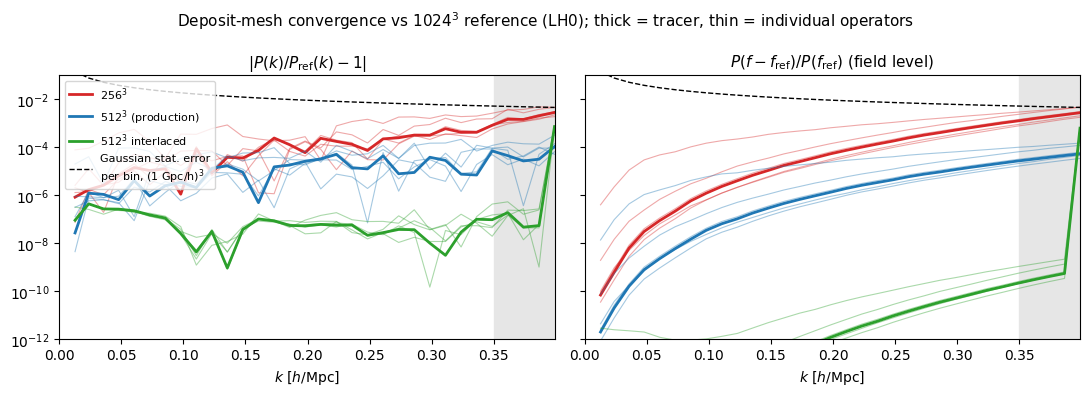

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

for ax, kind, title in zip(axes, ["pk", "pdiff"],
                           [r"$|P(k)/P_\mathrm{ref}(k) - 1|$",
                            r"$P(f - f_\mathrm{ref})/P(f_\mathrm{ref})$ (field level)"]):
    for c in cfgs:
        for op in ["tracer"] + ops:
            if kind == "pk":
                y = np.abs(res[f"pk_{op}_{c}"] / res[f"pk_{op}_{ref}"] - 1)
            else:
                y = res[f"pdiff_{op}_{c}"] / res[f"pk_{op}_{ref}"]
            is_tr = op == "tracer"
            ax.plot(k, y, color=cfg_colors[c], lw=2 if is_tr else 0.8, alpha=1 if is_tr else 0.4,
                    label=cfg_labels[c] if is_tr else None)
    ax.plot(k, sigma_frac, "k--", lw=1, label="Gaussian stat. error\nper bin, (1 Gpc/h)$^3$")
    ax.axvspan(kmax_analysis, k.max(), color="0.9", zorder=0)
    ax.set_yscale("log")
    ax.set_xlabel(r"$k$ [$h$/Mpc]")
    ax.set_title(title, fontsize=11)
    ax.set_xlim(0, k.max())
axes[0].set_ylim(1e-12, 1e-1)
axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle(rf"Deposit-mesh convergence vs $1024^3$ reference (LH0); thick = tracer, thin = individual operators", fontsize=11)
fig.tight_layout()
plt.show()

**Conclusion.** Relative to the $1024^3$ reference, the production $512^3$ deposit changes $P(k)$ of the tracer and of every operator by $\lesssim 2\times10^{-4}$ for $k \le 0.35\,h$/Mpc (tracer: $7\times10^{-5}$ at $k=0.35$), about two orders of magnitude below the per-bin statistical error of a single box ($\sim 0.5\%$). The test is sensitive: $256^3$ is ~10× worse and grows with $k$ as expected for aliasing. The $1024^3$ and interlaced-$512^3$ results, two independent anti-aliasing methods, agree to $\sim10^{-7}$, so the reference is converged and the $\sim10^{-4}$ residual in production really is aliasing. The CIC window itself differs by a few percent between $512^3$ and $1024^3$ at $k = 0.35$, yet the deconvolved fields agree to $\sim10^{-4}$, so the deconvolution is exact up to aliasing. (The $-7\times10^{-4}$ in `ng512i` at $k\approx0.40$ is an artifact of combining the interlaced grids on the $128^3$ Nyquist planes, beyond our $k$ range.)

*Paper text:* "We verified that depositing onto a $1024^3$ mesh changes the $k$-cut, deconvolved operator fields by at most $2\times10^{-4}$ in $P(k)$ for $k \le 0.35\,h\,\mathrm{Mpc}^{-1}$, so aliasing in the deposit step is negligible.\"